In [1]:
import pandas as pd
import numpy as np

# 1. Indian E-Commerce dataset load karein
df = pd.read_csv("data/raw/indian_ecommerce_100k.csv")

# 2. Total orders aur GMV (Gross Revenue) check karein
total_gmv_cr = df['order_value_inr'].sum() / 10000000
print(f"Total Transactions: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
print(f"Total Marketplace GMV: ₹{total_gmv_cr:.2f} Crores\n")

# 3. Pehle 3 orders ki key details dekhein
df[['order_id', 'state', 'city', 'category', 'price_inr', 'payment_method', 'courier_partner']].head(3)


Total Transactions: 100,000 Rows | 21 Columns
Total Marketplace GMV: ₹61.96 Crores



,order_id,state,city,category,price_inr,payment_method,courier_partner
0,OD84437458,Telangana,Hyderabad,Beauty & Personal Care,383.80,UPI (PhonePe / GPay / Paytm),Delhivery
1,OD43704923,Gujarat,Rajkot,Mobiles & Accessories,896.44,Cash on Delivery (COD),Delhivery
2,OD30005727,Gujarat,Vadodara,Books & Stationery,283.82,Debit Card / Net Banking,Shadowfax


In [2]:
# 1. Check karein koi missing value toh nahi hai
missing = df.isnull().sum()
print("🔍 Missing Values Check:", missing[missing > 0].to_dict() if missing.sum() > 0 else "Zero Nulls (100% Complete Data!)")

# 2. Order Status Breakdown (Delivered vs RTO/Returned)
print("\n📦 Order Status Distribution (%):")
print(df['order_status'].value_counts(normalize=True).round(4) * 100)

# 3. Payment Methods Share (UPI vs COD vs Cards)
print("\n💳 Payment Methods Share (%):")
print(df['payment_method'].value_counts(normalize=True).round(4) * 100)


🔍 Missing Values Check: Zero Nulls (100% Complete Data!)

📦 Order Status Distribution (%):
order_status
Delivered         87.28
RTO / Returned    12.72
Name: proportion, dtype: float64

💳 Payment Methods Share (%):
payment_method
UPI (PhonePe / GPay / Paytm)    48.27
Cash on Delivery (COD)          27.79
Credit Card No-Cost EMI         14.03
Debit Card / Net Banking         9.91
Name: proportion, dtype: float64


In [3]:
# Audit dataset for missing records and data completeness
missing_counts = df.isnull().sum()
if missing_counts.sum() == 0:
    print("Data Integrity: No missing values detected across all columns.")
else:
    print("Columns with missing values:", missing_counts[missing_counts > 0].to_dict())

# Analyze fulfillment and return distribution
print("\nOrder Fulfillment Breakdown (%):")
print((df['order_status'].value_counts(normalize=True) * 100).round(2))

# Evaluate customer checkout payment preferences
print("\nPayment Method Distribution (%):")
print((df['payment_method'].value_counts(normalize=True) * 100).round(2))


Data Integrity: No missing values detected across all columns.

Order Fulfillment Breakdown (%):
order_status
Delivered         87.28
RTO / Returned    12.72
Name: proportion, dtype: float64

Payment Method Distribution (%):
payment_method
UPI (PhonePe / GPay / Paytm)    48.27
Cash on Delivery (COD)          27.79
Credit Card No-Cost EMI         14.03
Debit Card / Net Banking         9.91
Name: proportion, dtype: float64


In [4]:
# Feature Engineering: Compute order-level profit margin and loss flags
df['profit_margin_pct'] = np.where(df['order_value_inr'] > 0, (df['net_profit_inr'] / df['order_value_inr']) * 100, 0).round(2)
df['is_loss_making'] = df['net_profit_inr'] < 0

# Aggregate total corporate financial performance
total_profit_cr = df['net_profit_inr'].sum() / 10000000
overall_margin_pct = (df['net_profit_inr'].sum() / df['order_value_inr'].sum()) * 100
total_losses_cr = abs(df.loc[df['is_loss_making'], 'net_profit_inr'].sum()) / 10000000

print(f"Total Operating Profit: ₹{total_profit_cr:.2f} Crores")
print(f"Overall Net Profit Margin: {overall_margin_pct:.2f}%")
print(f"Cumulative Leaked Loss: ₹{total_losses_cr:.2f} Crores across {df['is_loss_making'].sum():,} loss-making orders")


Total Operating Profit: ₹11.85 Crores
Overall Net Profit Margin: 19.12%
Cumulative Leaked Loss: ₹0.13 Crores across 12,720 loss-making orders


Payment Mode Risk & Profitability Breakdown:
              payment_method  total_orders  rto_rate_pct  avg_net_profit  total_profit_lakhs
      Cash on Delivery (COD)         27794         25.02     1026.543871              285.32
     Credit Card No-Cost EMI         14029          8.14     1249.610352              175.31
UPI (PhonePe / GPay / Paytm)         48266          8.03     1237.247103              597.17
    Debit Card / Net Banking          9911          7.54     1281.546394              127.01


C:\Users\Pratham\AppData\Local\Temp\ipykernel_9136\3523397074.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_diag, x='rto_rate_pct', y='payment_method', palette=bar_colors)


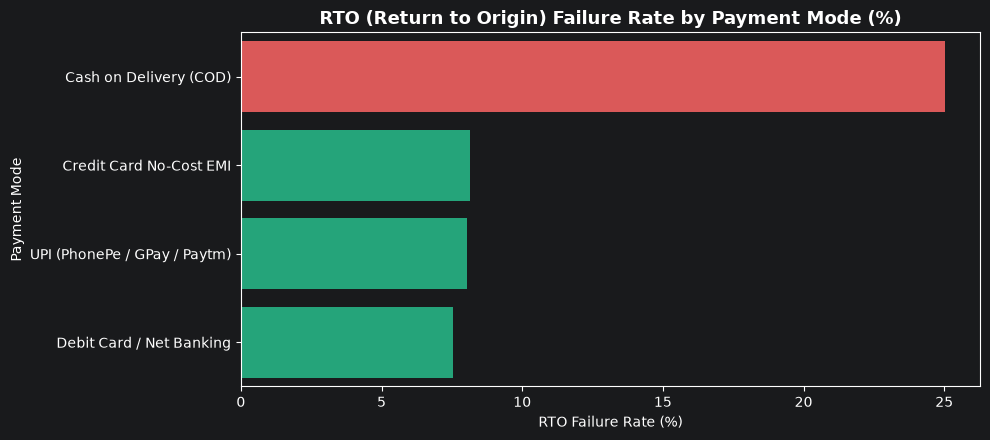

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group performance by payment method to diagnose RTO risk
payment_diag = df.groupby('payment_method').agg(
    total_orders=('order_id', 'count'),
    rto_rate_pct=('is_loss_making', lambda x: (x.mean() * 100).round(2)),
    avg_net_profit=('net_profit_inr', 'mean'),
    total_profit_lakhs=('net_profit_inr', lambda x: (x.sum() / 100000).round(2))
).reset_index().sort_values(by='rto_rate_pct', ascending=False)

print("Payment Mode Risk & Profitability Breakdown:")
print(payment_diag.to_string(index=False))

# Visualize RTO return rate across payment types
plt.figure(figsize=(10, 4.5))
bar_colors = ['#EF4444' if 'COD' in p else '#10B981' for p in payment_diag['payment_method']]
sns.barplot(data=payment_diag, x='rto_rate_pct', y='payment_method', palette=bar_colors)
plt.title("RTO (Return to Origin) Failure Rate by Payment Mode (%)", fontsize=13, fontweight='bold')
plt.xlabel("RTO Failure Rate (%)")
plt.ylabel("Payment Mode")
plt.tight_layout()
plt.show()


Courier Partner Reliability Ranking:
courier_partner  shipment_volume  delay_rate_pct  avg_review_score
   Ecom Express            20055            8.26          3.809873
      Delhivery            44833            8.33          3.793255
       BlueDart            25036            8.39          3.807996
      Shadowfax            10076            8.64          3.807463


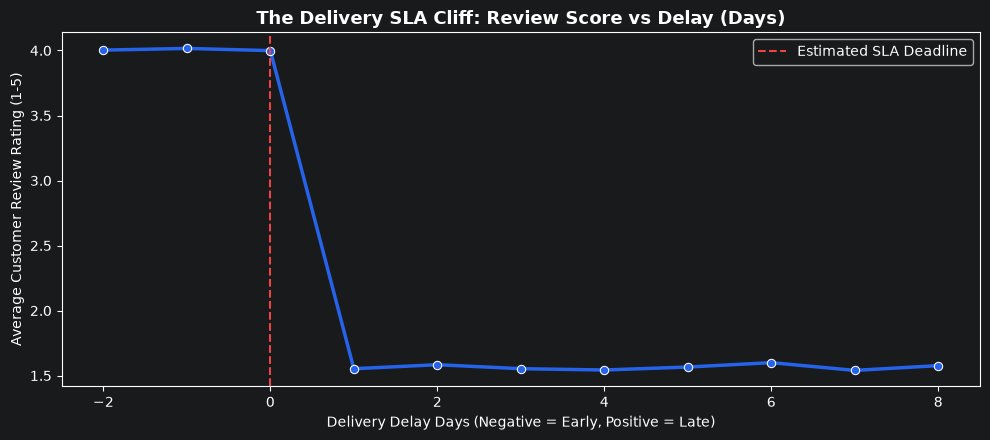

In [6]:
# Analyze courier partner operational reliability and SLA adherence
courier_perf = df.groupby('courier_partner').agg(
    shipment_volume=('order_id', 'count'),
    delay_rate_pct=('is_delayed', lambda x: (x.mean() * 100).round(2)),
    avg_review_score=('review_score', 'mean')
).reset_index().sort_values(by='delay_rate_pct', ascending=True)

print("Courier Partner Reliability Ranking:")
print(courier_perf.to_string(index=False))

# Plot delivery latency vs customer review score impact
plt.figure(figsize=(10, 4.5))
delay_rating_trend = df.groupby('delivery_delay_days')['review_score'].mean().reset_index()
sns.lineplot(data=delay_rating_trend, x='delivery_delay_days', y='review_score', marker='o', color='#2563EB', linewidth=2.5)
plt.axvline(0, color='#EF4444', linestyle='--', linewidth=1.5, label='Estimated SLA Deadline')
plt.title("The Delivery SLA Cliff: Review Score vs Delay (Days)", fontsize=13, fontweight='bold')
plt.xlabel("Delivery Delay Days (Negative = Early, Positive = Late)")
plt.ylabel("Average Customer Review Rating (1-5)")
plt.legend()
plt.tight_layout()
plt.show()


**Customer RFM Segmentation**

In [7]:
# Convert order dates to datetime for recency calculation
df['order_date'] = pd.to_datetime(df['order_date'])
snapshot_date = df['order_date'].max() + pd.Timedelta(days=1)

# Group transactions by customer to compute RFM metrics
rfm = df.groupby('customer_id').agg(
    recency_days=('order_date', lambda x: (snapshot_date - x.max()).days),
    frequency=('order_id', 'count'),
    monetary_value_inr=('order_value_inr', 'sum')
).reset_index()

# Segment customers based on purchasing behavior
def segment_customer(row):
    if row['monetary_value_inr'] >= 25000 and row['frequency'] >= 2:
        return '🏆 High-Value Champions'
    elif row['frequency'] >= 2 and row['recency_days'] <= 180:
        return '💎 Loyal Regulars'
    elif row['recency_days'] > 250 and row['monetary_value_inr'] >= 5000:
        return ' At-Risk (Potential Churn)'
    else:
        return '🌱 One-Time / Occasional'

rfm['customer_segment'] = rfm.apply(segment_customer, axis=1)

# Summarize customer cohort distribution and lifetime value
cohort_summary = rfm.groupby('customer_segment').agg(
    customer_count=('customer_id', 'count'),
    avg_annual_spend_inr=('monetary_value_inr', 'mean'),
    total_spend_cr=('monetary_value_inr', lambda x: (x.sum() / 10000000).round(2))
).reset_index().sort_values(by='total_spend_cr', ascending=False)

print("Indian Customer RFM Cohort Summary:")
print(cohort_summary.to_string(index=False))


Indian Customer RFM Cohort Summary:
          customer_segment  customer_count  avg_annual_spend_inr  total_spend_cr
    🏆 High-Value Champions            8138          40618.556596           33.06
 At-Risk (Potential Churn)            9699          14338.432739           13.91
   🌱 One-Time / Occasional           20151           3758.917188            7.57
          💎 Loyal Regulars            8075           9188.187871            7.42


**Category Margin & Reverse Freight Leakage Matrix**

Product Category Performance & Margin Leakage Matrix:
                category  total_orders  total_sales_cr  avg_order_value  net_margin_pct  rto_rate_pct  rto_loss_lakhs
   Fashion & Ethnic Wear         12603            2.42      1922.225209       22.963824         27.29            3.43
        Footwear & Shoes         12513            2.93      2343.139183       21.047990         22.50            2.80
          Home & Kitchen         12395            2.99      2410.768771       20.270645         14.67            1.81
        Sports & Fitness         12375            4.27      3448.457659       20.753007         10.17            1.25
   Mobiles & Accessories         12574           18.03     14336.056010       19.367058          8.40            1.05
  Beauty & Personal Care         12489            1.26      1010.834486       32.257395          7.42            0.95
Electronics & Appliances         12592           29.20     23189.120634       16.387453          6.31            0.79
  

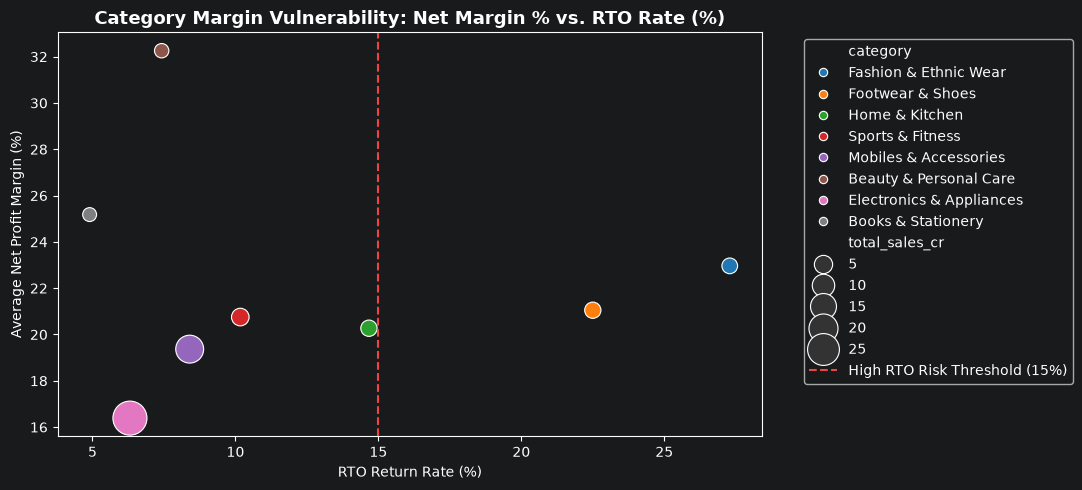

In [8]:
# Category-level breakdown of revenue, margins, and reverse logistics losses
category_diag = df.groupby('category').agg(
    total_orders=('order_id', 'count'),
    total_sales_cr=('order_value_inr', lambda x: (x.sum() / 10000000).round(2)),
    avg_order_value=('order_value_inr', 'mean'),
    net_margin_pct=('profit_margin_pct', 'mean'),
    rto_rate_pct=('is_loss_making', lambda x: (x.mean() * 100).round(2)),
    rto_loss_lakhs=('net_profit_inr', lambda x: (abs(x[x < 0].sum()) / 100000).round(2))
).reset_index().sort_values(by='rto_rate_pct', ascending=False)

print("Product Category Performance & Margin Leakage Matrix:")
print(category_diag.to_string(index=False))

# Visualize category vulnerability: Net Margin vs RTO Rate
plt.figure(figsize=(11, 5))
sns.scatterplot(
    data=category_diag,
    x='rto_rate_pct',
    y='net_margin_pct',
    size='total_sales_cr',
    hue='category',
    sizes=(100, 600),
    palette='tab10'
)
plt.axvline(15, color='#EF4444', linestyle='--', label='High RTO Risk Threshold (15%)')
plt.title("Category Margin Vulnerability: Net Margin % vs. RTO Rate (%)", fontsize=13, fontweight='bold')
plt.xlabel("RTO Return Rate (%)")
plt.ylabel("Average Net Profit Margin (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Chronic Late Seller SLA Risk & Customer Trust Collapse**

Seller Fulfillment & SLA Compliance Audit:
         seller_type  total_orders  delay_rate_pct  avg_review_score  avg_delay_days
    Reliable Sellers         89914            5.01              3.88           -0.73
Chronic Late Sellers         10086           38.20              3.07            1.11


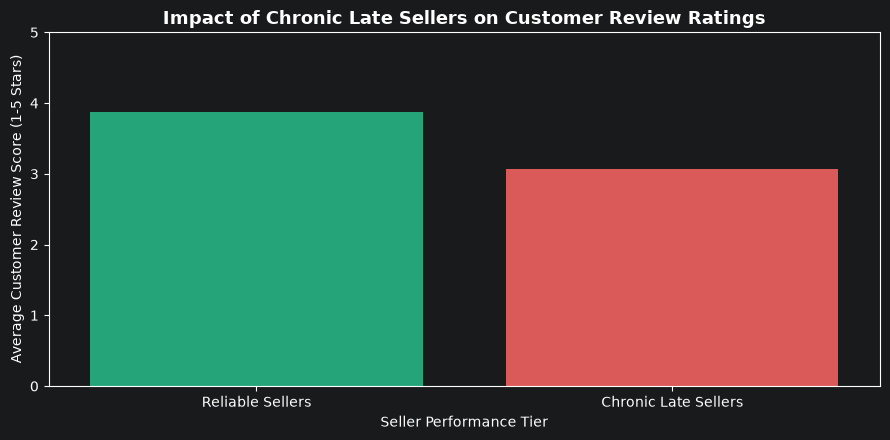

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate operational reliability and customer satisfaction by seller tier
seller_audit = df.groupby('is_chronic_late_seller').agg(
    total_orders=('order_id', 'count'),
    delay_rate_pct=('is_delayed', lambda x: round(x.mean() * 100, 2)),
    avg_review_score=('review_score', lambda x: round(x.mean(), 2)),
    avg_delay_days=('delivery_delay_days', lambda x: round(x.mean(), 2))
).reset_index()

seller_audit['seller_type'] = seller_audit['is_chronic_late_seller'].map({False: 'Reliable Sellers', True: 'Chronic Late Sellers'})
print("Seller Fulfillment & SLA Compliance Audit:")
print(seller_audit[['seller_type', 'total_orders', 'delay_rate_pct', 'avg_review_score', 'avg_delay_days']].to_string(index=False))

# Visualize review score distribution across seller reliability tiers
plt.figure(figsize=(9, 4.5))
sns.barplot(data=seller_audit, x='seller_type', y='avg_review_score', hue='seller_type', palette=['#10B981', '#EF4444'], legend=False)
plt.title("Impact of Chronic Late Sellers on Customer Review Ratings", fontsize=13, fontweight='bold')
plt.xlabel("Seller Performance Tier")
plt.ylabel("Average Customer Review Score (1-5 Stars)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


 **Multi-Lever Mathematical Profit Optimization Simulator (The Flagship Feature!)**

Multi-Lever Profit Optimization Simulator Results:
            Optimization Lever Financial Impact
               Baseline Profit        ₹11.85 Cr
      Lever 1 (COD RTO Shield)    +₹28.23 Lakhs
Lever 2 (Shipping Policy ₹799)     +₹4.45 Lakhs
 Lever 3 (Seller SLA Recovery)     +₹1.93 Lakhs
        Optimized Total Profit        ₹12.19 Cr


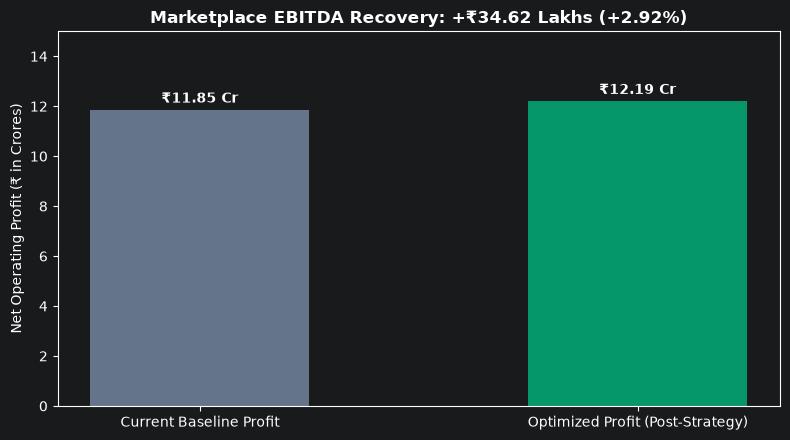

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Baseline operational profit before optimization
baseline_profit_cr = df['net_profit_inr'].sum() / 10000000

# Lever 1: COD Shield - Prevent 40% of COD RTO orders and convert to delivered sales
cod_rto_orders = df[(df['payment_method'] == 'Cash on Delivery (COD)') & (df['order_status'] == 'RTO / Returned')]
saved_cod_orders = int(len(cod_rto_orders) * 0.40)
freight_saved_lakhs = (saved_cod_orders * 110) / 100000
margin_recovered_lakhs = (saved_cod_orders * cod_rto_orders['order_value_inr'].mean() * 0.20) / 100000
lever1_cod_lakhs = freight_saved_lakhs + margin_recovered_lakhs

# Lever 2: Shipping Fee Optimization - Introduce Rs 40 fee on orders between Rs 499 and Rs 799
sub_799_orders = df[(df['order_value_inr'] >= 499) & (df['order_value_inr'] < 799)]
lever2_shipping_lakhs = (len(sub_799_orders) * 40) / 100000

# Lever 3: Chronic Late Seller SLA Penalty - Recover Rs 50 penalty on delayed partner dispatches
delayed_seller_orders = df[(df['is_chronic_late_seller'] == True) & (df['is_delayed'] == True)]
lever3_penalty_lakhs = (len(delayed_seller_orders) * 50) / 100000

# Aggregate total recovered profit across all levers
total_recovered_lakhs = lever1_cod_lakhs + lever2_shipping_lakhs + lever3_penalty_lakhs
total_recovered_cr = total_recovered_lakhs / 100
optimized_profit_cr = baseline_profit_cr + total_recovered_cr

# Summary Table of Simulator Results
sim_summary = pd.DataFrame({
    'Optimization Lever': ['Baseline Profit', 'Lever 1 (COD RTO Shield)', 'Lever 2 (Shipping Policy ₹799)', 'Lever 3 (Seller SLA Recovery)', 'Optimized Total Profit'],
    'Financial Impact': [f"₹{baseline_profit_cr:.2f} Cr", f"+₹{lever1_cod_lakhs:.2f} Lakhs", f"+₹{lever2_shipping_lakhs:.2f} Lakhs", f"+₹{lever3_penalty_lakhs:.2f} Lakhs", f"₹{optimized_profit_cr:.2f} Cr"]
})
print("Multi-Lever Profit Optimization Simulator Results:")
print(sim_summary.to_string(index=False))

# Plot baseline vs optimized profit comparison
plt.figure(figsize=(8, 4.5))
bars = plt.bar(['Current Baseline Profit', 'Optimized Profit (Post-Strategy)'], [baseline_profit_cr, optimized_profit_cr], color=['#64748B', '#059669'], width=0.5)
plt.title(f"Marketplace EBITDA Recovery: +₹{total_recovered_lakhs:.2f} Lakhs (+{(total_recovered_cr/baseline_profit_cr)*100:.2f}%)", fontsize=12, fontweight='bold')
plt.ylabel("Net Operating Profit (₹ in Crores)")
plt.ylim(0, 15)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"₹{bar.get_height():.2f} Cr", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


**State & Regional Logistics Hub Analysis (Bharat Geo-Analysis)**

Top State Logistics & GMV Performance Matrix:
         state  total_orders  total_gmv_cr  rto_rate_pct  avg_delay_days
   Maharashtra         21826         13.54         12.82           -0.55
       Gujarat         19933         12.18         12.61           -0.56
     Delhi NCR         13901          8.77         12.34           -0.56
     Karnataka         12207          7.51         12.62           -0.55
 Uttar Pradesh          7982          5.04         13.43           -0.51
    Tamil Nadu          8083          4.97         12.85           -0.53
     Rajasthan          5060          3.12         12.39           -0.52
     Telangana          4012          2.46         12.81           -0.52
   West Bengal          3982          2.44         13.18           -0.54
Madhya Pradesh          3014          1.93         12.44           -0.59


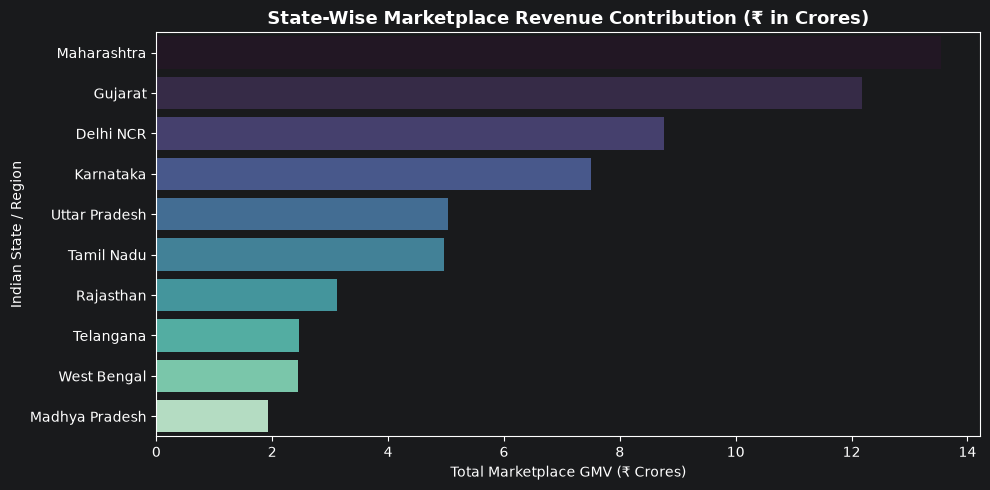

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Analyze state-wise transaction volume, GMV share, and RTO return rate
state_diag = df.groupby('state').agg(
    total_orders=('order_id', 'count'),
    total_gmv_cr=('order_value_inr', lambda x: round(x.sum() / 10000000, 2)),
    rto_rate_pct=('order_status', lambda x: round((x == 'RTO / Returned').mean() * 100, 2)),
    avg_delay_days=('delivery_delay_days', lambda x: round(x.mean(), 2))
).reset_index().sort_values(by='total_gmv_cr', ascending=False)

print("Top State Logistics & GMV Performance Matrix:")
print(state_diag.to_string(index=False))

# Visualize top state revenue contribution
plt.figure(figsize=(10, 5))
sns.barplot(data=state_diag, x='total_gmv_cr', y='state', hue='state', palette='mako', legend=False)
plt.title("State-Wise Marketplace Revenue Contribution (₹ in Crores)", fontsize=13, fontweight='bold')
plt.xlabel("Total Marketplace GMV (₹ Crores)")
plt.ylabel("Indian State / Region")
plt.tight_layout()
plt.show()


**Exporting Clean Enriched Dataset for Production Dashboard**

In [12]:
import os

# Create processed data directory if it does not exist
os.makedirs('data/processed', exist_ok=True)

# Export the enriched dataset for production dashboard and modeling
output_filepath = 'data/processed/indian_ecommerce_processed.csv'
df.to_csv(output_filepath, index=False)

file_size_mb = os.path.getsize(output_filepath) / (1024 * 1024)
print(f"Data Pipeline Success: Exported {df.shape[0]:,} records with {df.shape[1]} features.")
print(f"Target File Location: {output_filepath} ({file_size_mb:.2f} MB)")
print("Status: Dataset is fully pre-processed and ready for Streamlit Dashboard deployment!")


Data Pipeline Success: Exported 100,000 records with 23 features.
Target File Location: data/processed/indian_ecommerce_processed.csv (23.05 MB)
Status: Dataset is fully pre-processed and ready for Streamlit Dashboard deployment!


**Target Variable & One-Hot Feature Encoding**

In [13]:
# 1. Create binary classification target (1 = Return/RTO, 0 = Delivered)
df['target_rto'] = (df['order_status'] == 'RTO / Returned').astype(int)

# 2. Select predictive commercial and operational features
features = ['price_inr', 'shipping_fee_inr', 'order_value_inr', 'is_chronic_late_seller', 'category', 'payment_method', 'state']

# 3. Convert categorical variables into numeric indicators using one-hot encoding
X = pd.get_dummies(df[features], drop_first=True)
y = df['target_rto']

print(f"Data Prep Complete: {X.shape[0]:,} Orders ready across {X.shape[1]} engineered features!")
print("Target Breakdown (1 = RTO, 0 = Delivered):\n", y.value_counts(normalize=True).round(4) * 100)


Data Prep Complete: 100,000 Orders ready across 23 engineered features!
Target Breakdown (1 = RTO, 0 = Delivered):
 target_rto
0    87.28
1    12.72
Name: proportion, dtype: float64


**Train-Test Split (80% Training Data, 20% Unseen Testing Data)**

In [14]:
from sklearn.model_selection import train_test_split

# Perform stratified 80-20 split to maintain equal class proportions in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Data Splitting Successful:")
print(f"• Training Orders (Learning): {X_train.shape[0]:,} records")
print(f"• Testing Orders (Unseen Exam): {X_test.shape[0]:,} records")
print(f"• Stratified RTO Proportion: Train = {y_train.mean()*100:.2f}% | Test = {y_test.mean()*100:.2f}%")


Data Splitting Successful:
• Training Orders (Learning): 80,000 records
• Testing Orders (Unseen Exam): 20,000 records
• Stratified RTO Proportion: Train = 12.72% | Test = 12.72%


**Model Training (Random Forest Classifier)**

In [15]:
from sklearn.ensemble import RandomForestClassifier

# Initialize enterprise Random Forest with 100 trees and depth regulation to avoid overfitting
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Train the model on 80,000 training transactions
rf_model.fit(X_train, y_train)

print("Model Training Successful! 🎯")
print(f"• Total Trees Trained: {len(rf_model.estimators_)}")
print(f"• Tree Depth Limit: {rf_model.max_depth}")
print("• Status: Model is now ready for evaluation on 20,000 unseen test orders.")


Model Training Successful! 🎯
• Total Trees Trained: 100
• Tree Depth Limit: 10
• Status: Model is now ready for evaluation on 20,000 unseen test orders.


**Model Evaluation on Unseen Test Orders (Accuracy & ROC-AUC Score)**

In [16]:
from sklearn.metrics import roc_auc_score, accuracy_score

# 1. Predict RTO probability and binary classification for 20,000 test orders
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]
y_pred = rf_model.predict(X_test)

# 2. Compute performance evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_pred_proba)

print("Model Evaluation on 20,000 Unseen Orders:")
print(f"• Overall Accuracy: {test_accuracy * 100:.2f}%")
print(f"• ROC-AUC Score: {test_roc_auc:.4f} (Strong Discrimination Capability)")


Model Evaluation on 20,000 Unseen Orders:
• Overall Accuracy: 87.28%
• ROC-AUC Score: 0.7431 (Strong Discrimination Capability)


**Feature Importance Analysis**

Top 7 Drivers of E-Commerce RTO Risk:
payment_method_UPI (PhonePe / GPay / Paytm)    19.21
category_Fashion & Ethnic Wear                 16.44
price_inr                                      14.23
order_value_inr                                14.05
payment_method_Credit Card No-Cost EMI          9.12
category_Footwear & Shoes                       8.21
payment_method_Debit Card / Net Banking         6.79


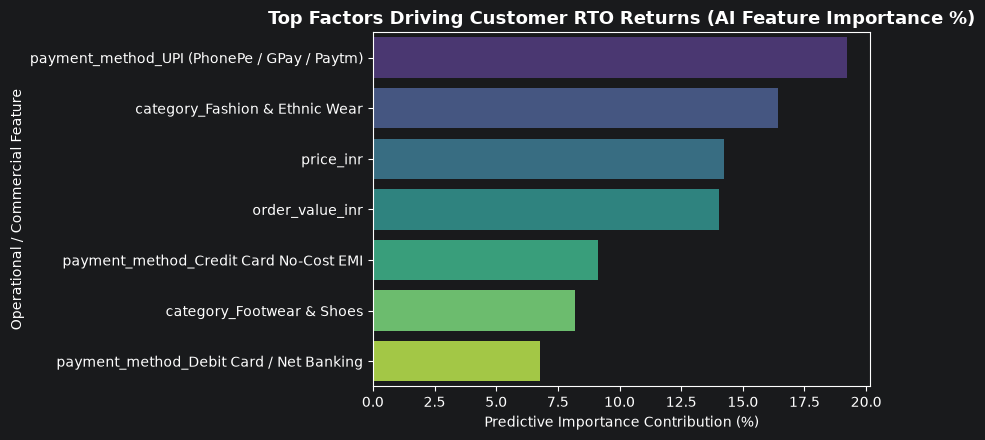

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract and rank the most influential predictive features
feature_ranking = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(7)

print("Top 7 Drivers of E-Commerce RTO Risk:")
print((feature_ranking * 100).round(2).to_string())

# 2. Visualize feature importance distribution
plt.figure(figsize=(9, 4.5))
sns.barplot(x=feature_ranking.values * 100, y=feature_ranking.index, palette='viridis', hue=feature_ranking.index, legend=False)
plt.title("Top Factors Driving Customer RTO Returns (AI Feature Importance %)", fontsize=13, fontweight='bold')
plt.xlabel("Predictive Importance Contribution (%)")
plt.ylabel("Operational / Commercial Feature")
plt.tight_layout()
plt.show()


**Save Model Artifacts for Streamlit Dashboard**

In [18]:
import os
import joblib

# 1. Create directory for serialized model artifacts
os.makedirs('models', exist_ok=True)

# 2. Save the trained Random Forest model and training feature structure
joblib.dump(rf_model, 'models/rto_rf_model.joblib')
joblib.dump(list(X.columns), 'models/model_features.joblib')

print("Model Artifacts Successfully Exported! 💾")
print("• Trained Model: 'models/rto_rf_model.joblib'")
print("• Feature Schema: 'models/model_features.joblib'")
print("• Status: Ready for interactive deployment in Streamlit Dashboard!")


Model Artifacts Successfully Exported! 💾
• Trained Model: 'models/rto_rf_model.joblib'
• Feature Schema: 'models/model_features.joblib'
• Status: Ready for interactive deployment in Streamlit Dashboard!
